In [1]:
!pip install roboflow -q

from google.colab import userdata
from roboflow import Roboflow

ROBOFLOW_API_KEY = userdata.get("ROBOFLOW_API_KEY")

rf = Roboflow(api_key=ROBOFLOW_API_KEY)
project = rf.workspace("trainingbimacameravision").project("potholedetectionyolov8-5igmy")
version = project.version(1)
dataset = version.download("yolov8")

print("Downloaded to:", dataset.location)

loading Roboflow workspace...
loading Roboflow project...

Downloaded to: /content/tcn-ai-ml-45days/Pothole_Defect_Detector/PotholeDetectionYOLOv8-1


In [2]:
import shutil, os

downloaded_path = dataset.location
target_path = "/content/tcn-ai-ml-45days/Pothole_Defect_Detector/data/PotholeDetectionYOLOv8-1"

if downloaded_path != target_path and os.path.exists(downloaded_path):
    shutil.move(downloaded_path, target_path)

print("Dataset at:", target_path)

Dataset at: /content/tcn-ai-ml-45days/Pothole_Defect_Detector/data/PotholeDetectionYOLOv8-1


In [3]:
import os
print(os.listdir("/content/tcn-ai-ml-45days/Pothole_Defect_Detector/data"))

['PotholeDetectionYOLOv8-1']


In [4]:
dataset_path = "/content/tcn-ai-ml-45days/Pothole_Defect_Detector/data/PotholeDetectionYOLOv8-1"

with open(f"{dataset_path}/data.yaml") as f:
    print(f.read())

names:
- potholes
nc: 1
roboflow:
  license: CC BY 4.0
  project: potholedetectionyolov8-5igmy
  url: https://universe.roboflow.com/trainingbimacameravision/potholedetectionyolov8-5igmy/dataset/1
  version: 1
  workspace: trainingbimacameravision
test: ../test/images
train: ../train/images
val: ../valid/images



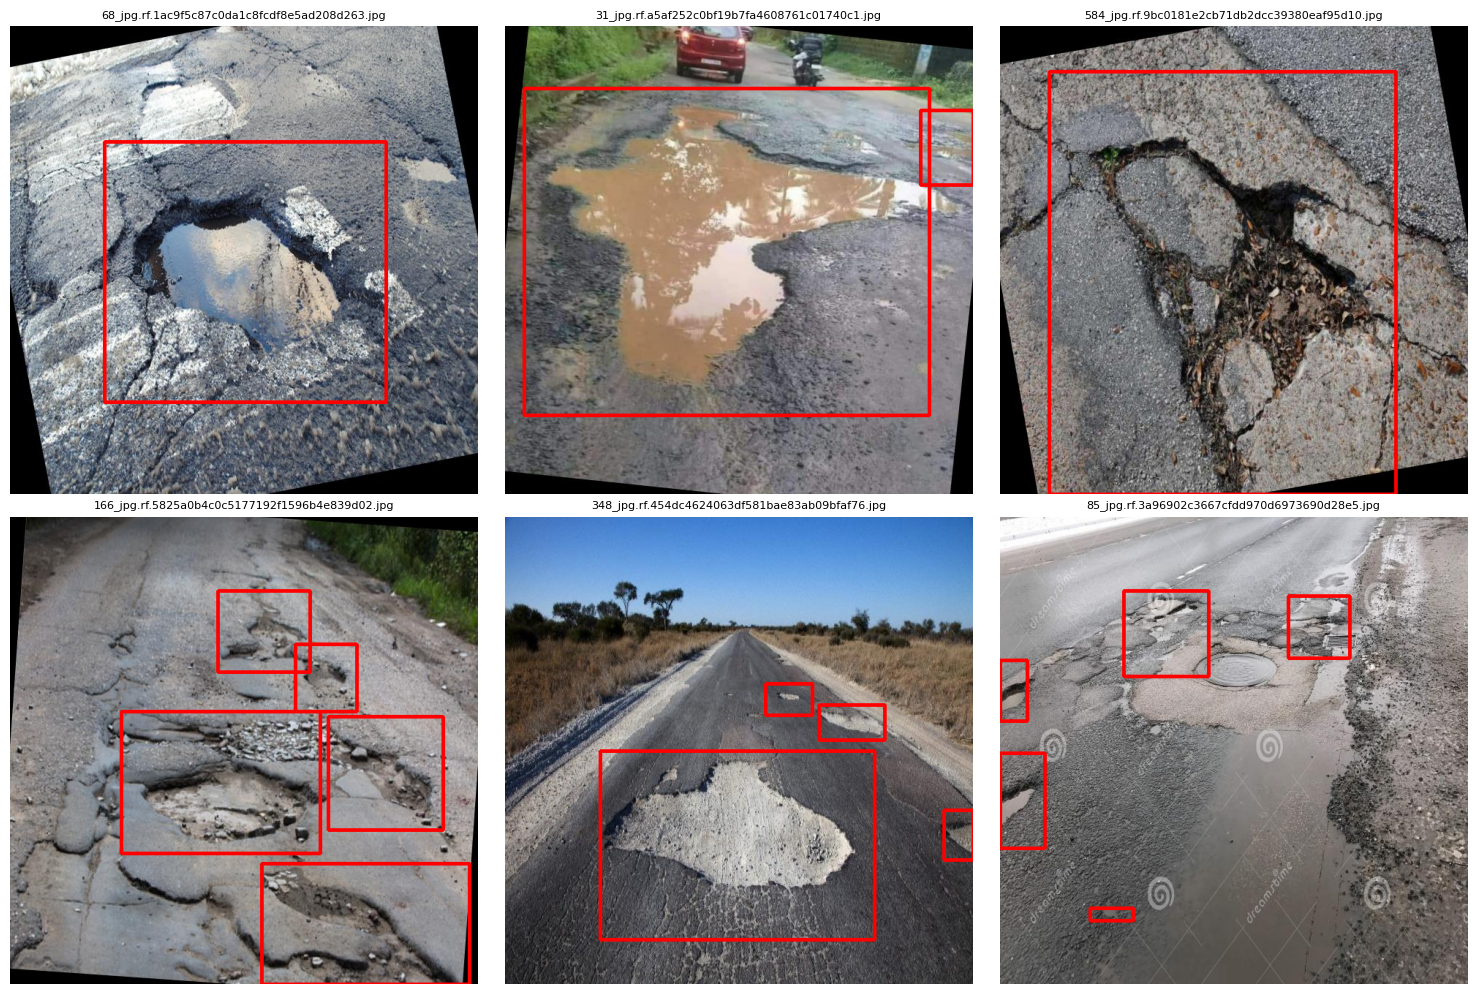

In [5]:
import cv2
import matplotlib.pyplot as plt
import os
import random

dataset_path = "/content/tcn-ai-ml-45days/Pothole_Defect_Detector/data/PotholeDetectionYOLOv8-1"
train_img_dir = f"{dataset_path}/train/images"
train_lbl_dir = f"{dataset_path}/train/labels"

image_files = os.listdir(train_img_dir)
sample_files = random.sample(image_files, 6)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for ax, img_name in zip(axes, sample_files):
    img_path = f"{train_img_dir}/{img_name}"
    label_path = f"{train_lbl_dir}/{os.path.splitext(img_name)[0]}.txt"

    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]

    if os.path.exists(label_path):
        with open(label_path) as f:
            for line in f:
                cls, xc, yc, bw, bh = map(float, line.split())
                x1 = int((xc - bw / 2) * w)
                y1 = int((yc - bh / 2) * h)
                x2 = int((xc + bw / 2) * w)
                y2 = int((yc + bh / 2) * h)
                cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 0), 3)

    ax.imshow(img)
    ax.set_title(img_name, fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.savefig("/content/phase2_sample_annotations.png", dpi=100)
plt.show()